<a href="https://colab.research.google.com/github/asegura4488/EDCO_IntroCienciaDatos/blob/main/Semana6/Analisis_precio_dolar_TRM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¿Qué podemos aprender del precio del dólar? 📈
### Análisis de la TRM colombiana con Python — nivel introductorio

**Objetivo.** Aprender a estudiar datos reales de una serie temporal, desde gráficas y estadística descriptiva hasta medidas sencillas de riesgo.

Con este notebook responderemos preguntas como: ¿cuándo fue más caro el dólar?, ¿cuánto subió o bajó entre observaciones?, ¿qué tan variable fue su precio?, ¿qué pérdidas habría enfrentado quien tenía dólares o quien necesitaba comprarlos?

**Datos:** archivo `TasaCambioHistorico.csv` que acompaña este notebook; comprende diciembre de 1991 a marzo de 2023. **No incluye cotizaciones actuales.**

> **Convención:** el precio se expresa en **COP por 1 USD**. Para ordenar las observaciones utilizamos `VIGENCIADESDE`, es decir, el inicio de la vigencia. Una fila puede abarcar varios días: por eso los cambios entre filas son cambios **entre registros consecutivos**, no necesariamente entre días calendario seguidos.

**Herramientas:** solamente `pandas`, `numpy` y `matplotlib`; no se necesitan modelos sofisticados.

## 1. Importar bibliotecas y cargar los datos

Coloca el CSV en la misma carpeta del notebook. Si trabajas en **Google Colab**, el código te pedirá subirlo cuando no lo encuentre.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path


In [2]:
from google.colab import drive
from google.colab import files
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [5]:
os.chdir('/content/drive/MyDrive/EDCO_IntroCienciaDatos/Semana6')
!ls

Analisis_precio_dolar_TRM.ipynb  Datos


In [6]:
archivo = Path("Datos/TasaCambioHistorico.csv")

if not archivo.exists():
    try:
        from google.colab import files
        print("Selecciona el archivo TasaCambioHistorico.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Coloca TasaCambioHistorico.csv junto al notebook")

df = pd.read_csv(archivo)
df.head()

,VALOR,UNIDAD,VIGENCIADESDE,VIGENCIAHASTA
0,4761.64,COP,22/12/2022,22/12/2022
1,4781.28,COP,20/12/2022,20/12/2022
2,4802.48,COP,17/12/2022,19/12/2022
3,4836.24,COP,13/12/2022,13/12/2022
4,4815.99,COP,10/12/2022,12/12/2022


## 2. Preparar las fechas y el precio

La columna `VALOR` contiene el precio en pesos de un dólar. La fecha del CSV viene como `día/mes/año`; la convertimos explícitamente para no confundir día y mes. Luego ordenamos las filas cronológicamente.

In [7]:
df["Fecha"] = pd.to_datetime(df["VIGENCIADESDE"], format="%d/%m/%Y")
df = df.rename(columns={"VALOR": "Precio"})
df = df[["Fecha", "Precio"]].sort_values("Fecha").reset_index(drop=True)

print("Registros:", len(df))
print("Desde:", df["Fecha"].min().date())
print("Hasta:", df["Fecha"].max().date())
print("Valores faltantes:", df.isna().sum().to_dict())
print("Fechas repetidas:", df["Fecha"].duplicated().sum())
df.head()

Registros: 7527
Desde: 1991-12-02
Hasta: 2023-03-23
Valores faltantes: {'Fecha': 0, 'Precio': 0}
Fechas repetidas: 0


,Fecha,Precio
0,1991-12-02,643.42
1,1991-12-03,639.22
2,1991-12-04,635.70
3,1991-12-05,631.51
4,1991-12-06,627.16


## 3. Historia del precio del dólar

**Pregunta:** ¿cómo ha cambiado a largo plazo el número de pesos necesarios para comprar un dólar?

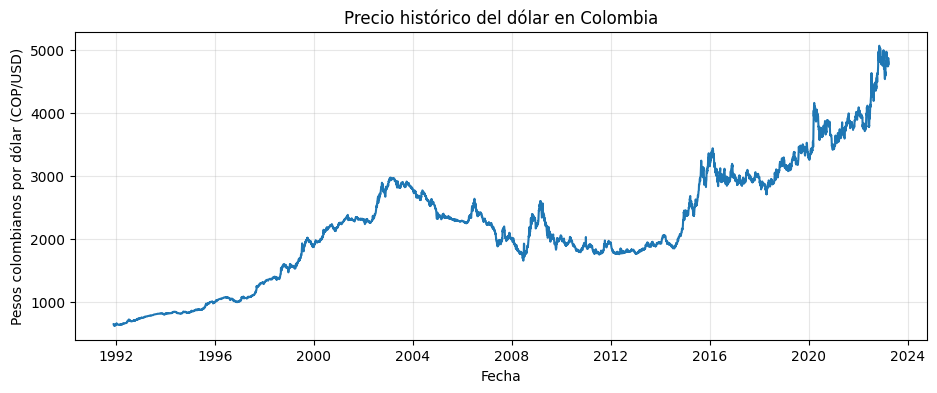

In [8]:
plt.figure(figsize=(11, 4))
plt.plot(df["Fecha"], df["Precio"])
plt.title("Precio histórico del dólar en Colombia")
plt.xlabel("Fecha")
plt.ylabel("Pesos colombianos por dólar (COP/USD)")
plt.grid(alpha=0.3)
plt.show()

También podemos comparar los **promedios anuales** (calculados sobre los registros disponibles, no ponderados por días de vigencia).

In [9]:
resumen_anual = df.groupby(df["Fecha"].dt.year)["Precio"].agg(
    ["mean", "min", "max"]
).round(2)
resumen_anual.columns = ["Promedio", "Mínimo", "Máximo"]

print("Últimos años del archivo:")
display(resumen_anual.tail(8))

Últimos años del archivo:


,Promedio,Mínimo,Máximo
Fecha,,,
2016,3050.97,2833.78,3434.89
2017,2950.54,2837.90,3092.65
2018,2956.05,2705.34,3289.69
2019,3282.26,3072.01,3522.48
2020,3696.31,3253.89,4153.91
2021,3749.12,3420.78,4023.68
2022,4251.47,3706.95,5061.21
2023,4762.67,4531.75,4989.58


## 4. Escoger un año para estudiar con más detalle

Puedes cambiar **solo la variable `ANIO`**. Recomendamos comenzar por `2022` porque tiene bastantes observaciones; `2023` termina en marzo y **no es un año completo**.

In [10]:
ANIO = 2022  # Prueba también 2020, 2021 o 2023

año = df[df["Fecha"].dt.year == ANIO].copy().reset_index(drop=True)
if len(año) < 2:
    raise ValueError("No hay suficientes registros para ese año")

print(f"Año: {ANIO} | Registros: {len(año)}")
print("Primera fecha:", año["Fecha"].iloc[0].date())
print("Última fecha:", año["Fecha"].iloc[-1].date())
año.head()

Año: 2022 | Registros: 238
Primera fecha: 2022-01-04
Última fecha: 2022-12-30


,Fecha,Precio
0,2022-01-04,4082.75
1,2022-01-05,4084.11
2,2022-01-06,4042.36
3,2022-01-07,4039.31
4,2022-01-08,4043.46


## 5. Estadística descriptiva

Las medidas más simples ya responden preguntas útiles:

- **Media y mediana:** ¿cuál fue el precio típico?
- **Mínimo y máximo:** ¿entre qué valores osciló?
- **Variación del periodo:** ¿cuánto cambió desde la primera hasta la última observación?

La variación porcentual de un precio inicial $P_0$ a uno final $P_f$ es

$$\text{Variación (\%)}=\left(\frac{P_f}{P_0}-1\right)100.$$

In [11]:
precio_inicio = año["Precio"].iloc[0]
precio_fin = año["Precio"].iloc[-1]
variacion = (precio_fin / precio_inicio - 1) * 100

print(f"Precio promedio: ${año['Precio'].mean():,.2f} COP")
print(f"Mediana:         ${año['Precio'].median():,.2f} COP")
print(f"Mínimo:          ${año['Precio'].min():,.2f} COP")
print(f"Máximo:          ${año['Precio'].max():,.2f} COP")
print(f"Precio inicial:  ${precio_inicio:,.2f} COP")
print(f"Precio final:    ${precio_fin:,.2f} COP")
print(f"Cambio total:    {variacion:+.2f}%")

Precio promedio: $4,251.47 COP
Mediana:         $4,140.54 COP
Mínimo:          $3,706.95 COP
Máximo:          $5,061.21 COP
Precio inicial:  $4,082.75 COP
Precio final:    $4,810.20 COP
Cambio total:    +17.82%


## 6. ¿Cuánto cambia el precio entre dos registros?

Si $P_t$ es el precio de una observación, podemos calcular:

**Cambio en pesos:** $\Delta P_t=P_t-P_{t-1}$.

**Retorno simple:** $r_t=\dfrac{P_t-P_{t-1}}{P_{t-1}}$.

**Retorno logarítmico:** $g_t=\ln\left(\dfrac{P_t}{P_{t-1}}\right)$.

En Pandas los cálculos se hacen directamente, sin escribir ciclos `for`. Multiplicamos por 100 para mostrar los retornos en **porcentaje**. La primera fila no tiene cambio porque no hay observación anterior *dentro del año elegido*.

In [12]:
año["Cambio_COP"] = año["Precio"].diff()
año["Retorno_%"] = año["Precio"].pct_change() * 100
año["Retorno_log_%"] = np.log(año["Precio"] / año["Precio"].shift(1)) * 100

display(año.head(8).round(3))

,Fecha,Precio,Cambio_COP,Retorno_%,Retorno_log_%
0,2022-01-04,4082.75,NaN,NaN,NaN
1,2022-01-05,4084.11,1.36,0.033,0.033
2,2022-01-06,4042.36,-41.75,-1.022,-1.028
3,2022-01-07,4039.31,-3.05,-0.075,-0.075
4,2022-01-08,4043.46,4.15,0.103,0.103
5,2022-01-12,4011.65,-31.81,-0.787,-0.790
6,2022-01-13,3970.08,-41.57,-1.036,-1.042
7,2022-01-14,3950.40,-19.68,-0.496,-0.497


## 7. Precio y promedio móvil

Una **media móvil de 20 registros** permite suavizar fluctuaciones y observar mejor la tendencia local. No es una predicción de lo que ocurrirá después.

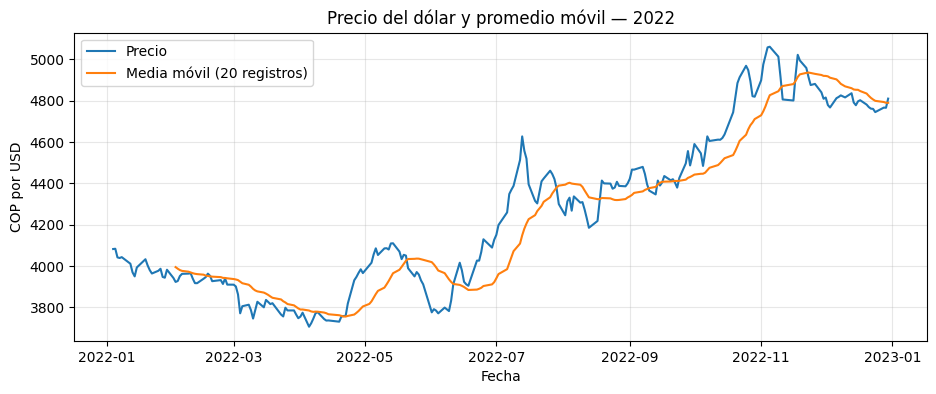

In [13]:
año["Media_movil_20"] = año["Precio"].rolling(20).mean()

plt.figure(figsize=(11, 4))
plt.plot(año["Fecha"], año["Precio"], label="Precio")
plt.plot(año["Fecha"], año["Media_movil_20"], label="Media móvil (20 registros)")
plt.title(f"Precio del dólar y promedio móvil — {ANIO}")
plt.ylabel("COP por USD")
plt.xlabel("Fecha")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. ¿Qué tan grandes son las subidas y las bajadas?

El histograma muestra la distribución de los **retornos porcentuales**. Además calculamos la frecuencia histórica de subidas y bajadas y la probabilidad empírica de observar un cambio superior al 1 % en magnitud.

Estas frecuencias describen el periodo analizado: **no son probabilidades garantizadas para el futuro**.

Retorno medio entre registros:  +0.074%
Desviación estándar:           1.029%
Registros con subida:          50.2%
Registros con bajada:          49.8%
Cambio mayor que 1% en valor absoluto: 27.0%


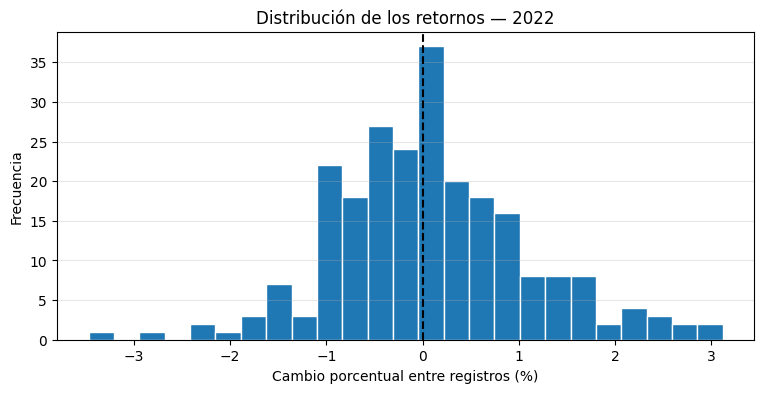

In [14]:
retornos = año["Retorno_%"].dropna()

print(f"Retorno medio entre registros:  {retornos.mean():+.3f}%")
print(f"Desviación estándar:           {retornos.std():.3f}%")
print(f"Registros con subida:          {(retornos > 0).mean() * 100:.1f}%")
print(f"Registros con bajada:          {(retornos < 0).mean() * 100:.1f}%")
print(f"Cambio mayor que 1% en valor absoluto: {(retornos.abs() > 1).mean() * 100:.1f}%")

plt.figure(figsize=(9, 4))
plt.hist(retornos, bins=25, edgecolor="white")
plt.axvline(0, color="black", linestyle="--")
plt.title(f"Distribución de los retornos — {ANIO}")
plt.xlabel("Cambio porcentual entre registros (%)")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 9. ¿Cuándo ocurrieron los cambios más grandes?

La siguiente tabla identifica los cinco movimientos más grandes, hacia arriba o hacia abajo, según su **valor absoluto**.

In [15]:
indices = año["Retorno_%"].abs().nlargest(5).index
movimientos = año.loc[indices, ["Fecha", "Precio", "Cambio_COP", "Retorno_%"]]
display(movimientos.sort_values("Fecha").round(3))

,Fecha,Precio,Cambio_COP,Retorno_%
74,2022-04-26,3931.74,112.67,2.950
99,2022-06-01,3776.52,-135.82,-3.472
113,2022-06-22,4026.92,121.87,3.121
125,2022-07-12,4513.28,125.01,2.849
129,2022-07-16,4395.63,-124.02,-2.744


## 10. Volatilidad: ¿cuánto fluctúa la tasa de cambio?

La **desviación estándar de los retornos** es una medida sencilla de volatilidad. También podemos calcular una volatilidad móvil usando los **20 registros más recientes**:

$$\sigma_t=\operatorname{desv.est.}(r_{t-19},\ldots,r_t).$$

Cuanto mayor sea $\sigma_t$, mayores han sido las fluctuaciones recientes. Esto mide variabilidad, no necesariamente pérdida.

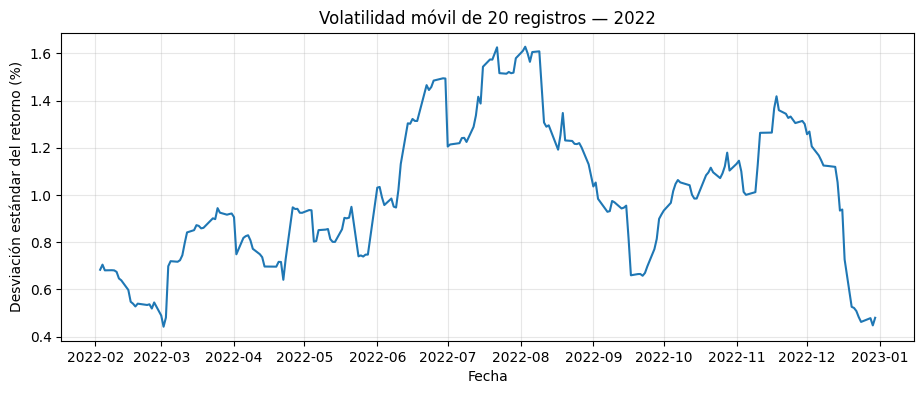

In [16]:
año["Volatilidad_20_%"] = año["Retorno_%"].rolling(20).std()

plt.figure(figsize=(11, 4))
plt.plot(año["Fecha"], año["Volatilidad_20_%"])
plt.title(f"Volatilidad móvil de 20 registros — {ANIO}")
plt.ylabel("Desviación estándar del retorno (%)")
plt.xlabel("Fecha")
plt.grid(alpha=0.3)
plt.show()

## 11. ¿Cómo fue el cambio de un mes a otro?

Tomamos el **último precio registrado de cada mes** y calculamos su variación respecto al mes anterior. En el primer mes no hay comparación disponible dentro de este subconjunto.

,Precio final del mes,Cambio respecto al mes anterior (%)
Fecha,,
2022-01,3982.60,NaN
2022-02,3910.64,-1.81
2022-03,3748.15,-4.16
2022-04,3966.27,5.82
2022-05,3912.34,-1.36
2022-06,4127.47,5.50
2022-07,4300.30,4.19
2022-08,4400.16,2.32
2022-09,4532.07,3.00


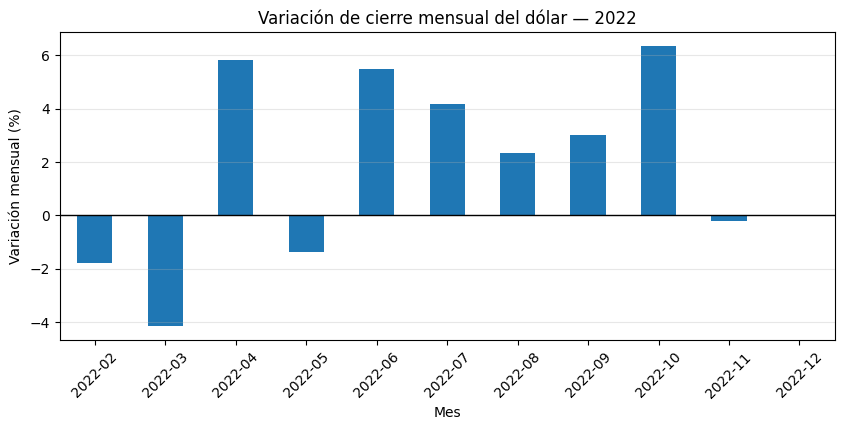

In [17]:
mensual = año.groupby(año["Fecha"].dt.to_period("M"))["Precio"].last()
variacion_mensual = mensual.pct_change() * 100

display(pd.DataFrame({"Precio final del mes": mensual,
                      "Cambio respecto al mes anterior (%)": variacion_mensual}).round(2))

variacion_mensual.dropna().plot(kind="bar", figsize=(10, 4))
plt.axhline(0, color="black", linewidth=1)
plt.title(f"Variación de cierre mensual del dólar — {ANIO}")
plt.ylabel("Variación mensual (%)")
plt.xlabel("Mes")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 12. Riesgo financiero: VaR y CVaR históricos

El mismo movimiento puede beneficiar a una persona y perjudicar a otra:

- **Si tengo dólares y los valoro en pesos:** pierdo valor cuando el dólar **baja**. La pérdida porcentual es $L_{\mathrm{tenedor}}=-r_t$.
- **Si necesito comprar dólares con pesos:** aumentan mis costos cuando el dólar **sube**. La pérdida relativa, entendida como mayor costo, es $L_{\mathrm{comprador}}=r_t$.

Para una serie de pérdidas $L$, definimos:

- **VaR histórico al 95 %:** percentil 95 de las pérdidas. Es un **umbral de pérdida** que el 95 % de los movimientos observados no superó; el 5 % restante sí pudo superarlo.
- **CVaR histórico al 95 %:** promedio de las pérdidas que están en el 5 % de la cola superior (aquí calculado con $L \geq \mathrm{VaR}$).

No suponen normalidad. Son **estimaciones retrospectivas sobre un intervalo entre registros** y no una garantía de pérdidas máximas futuras.

In [18]:
perdida_tenedor = -retornos
perdida_comprador = retornos

VaR_tenedor = perdida_tenedor.quantile(0.95)
CVaR_tenedor = perdida_tenedor[perdida_tenedor >= VaR_tenedor].mean()

VaR_comprador = perdida_comprador.quantile(0.95)
CVaR_comprador = perdida_comprador[perdida_comprador >= VaR_comprador].mean()

riesgos = pd.DataFrame({
    "VaR 95% (%)": [VaR_tenedor, VaR_comprador],
    "CVaR 95% (%)": [CVaR_tenedor, CVaR_comprador]
}, index=["Persona que tiene USD", "Persona que compra USD"])

display(riesgos.round(3))

,VaR 95% (%),CVaR 95% (%)
Persona que tiene USD,1.461,2.010
Persona que compra USD,2.027,2.514


Visualicemos las pérdidas de **quien tiene dólares**. La línea marca el VaR histórico; el área a su derecha corresponde a movimientos especialmente desfavorables para esa persona.

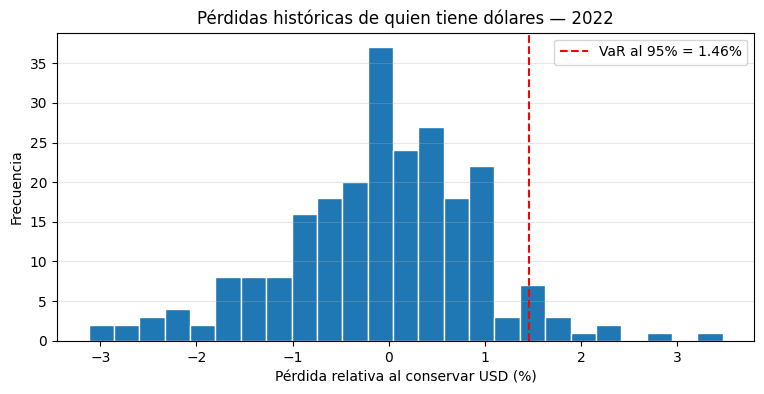

In [19]:
plt.figure(figsize=(9, 4))
plt.hist(perdida_tenedor, bins=25, edgecolor="white")
plt.axvline(VaR_tenedor, color="red", linestyle="--",
            label=f"VaR al 95% = {VaR_tenedor:.2f}%")
plt.title(f"Pérdidas históricas de quien tiene dólares — {ANIO}")
plt.xlabel("Pérdida relativa al conservar USD (%)")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

## 13. Traducir el riesgo a pesos colombianos

**Ejemplo:** para una posición de **1.000 USD**, ¿a cuántos pesos corresponde el VaR histórico? Tomamos como referencia el **último precio del año elegido**, no una cotización actual.

$$\text{VaR en COP (aprox.)}=\text{Monto USD}\times \text{Precio de referencia}\times \frac{\text{VaR(\%)}}{100}.$$

Esta conversión es una ilustración proporcional bajo movimientos porcentuales similares a los históricos; **no es una pérdida prevista ni un riesgo garantizado**.

In [20]:
MONTO_USD = 1000
precio_referencia = año["Precio"].iloc[-1]
valor_posicion = MONTO_USD * precio_referencia

print(f"Posición: {MONTO_USD:,} USD ≈ ${valor_posicion:,.0f} COP")
print(f"VaR para quien tiene USD:  ${valor_posicion * VaR_tenedor / 100:,.0f} COP")
print(f"VaR para quien compra USD: ${valor_posicion * VaR_comprador / 100:,.0f} COP")

Posición: 1,000 USD ≈ $4,810,200 COP
VaR para quien tiene USD:  $70,260 COP
VaR para quien compra USD: $97,517 COP


## 14. ¿Cuánto llegó a caer el dólar desde un máximo anterior?

El **drawdown** permite medir la caída porcentual respecto al mayor precio registrado *hasta ese momento*:

$$D_t=\left(\frac{P_t}{\max(P_1,\ldots,P_t)}-1\right)100.$$

Es útil para estudiar a alguien que **posee dólares**: un valor de $-10\%$ significa que el precio cayó 10 % desde un máximo observado anteriormente dentro del año. La caída máxima del periodo es el mínimo de $D_t$.

Caída máxima desde un máximo anterior: -9.55%


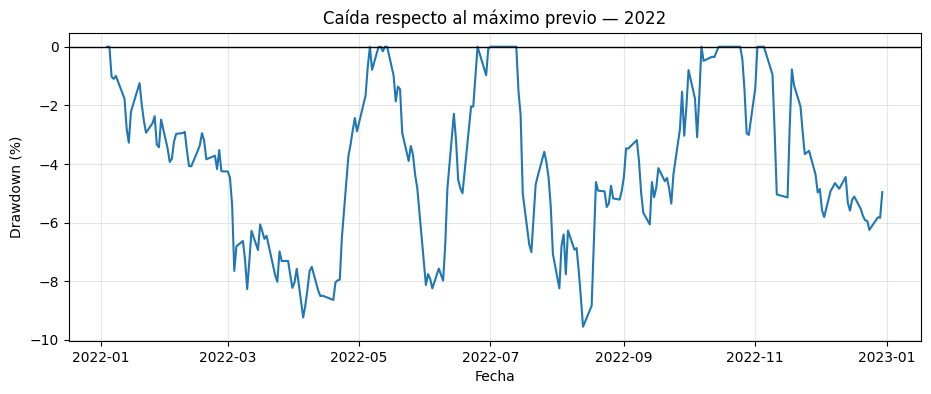

In [21]:
año["Maximo_previo"] = año["Precio"].cummax()
año["Drawdown_%"] = (año["Precio"] / año["Maximo_previo"] - 1) * 100

print(f"Caída máxima desde un máximo anterior: {año['Drawdown_%'].min():.2f}%")

plt.figure(figsize=(11, 4))
plt.plot(año["Fecha"], año["Drawdown_%"])
plt.axhline(0, color="black", linewidth=1)
plt.title(f"Caída respecto al máximo previo — {ANIO}")
plt.ylabel("Drawdown (%)")
plt.xlabel("Fecha")
plt.grid(alpha=0.3)
plt.show()

## 15. Una comparación sencilla entre años

Para comprobar si un periodo fue más volátil que otro, calculamos la **desviación estándar de los retornos dentro de cada año**. Así evitamos confundir un precio más alto con una mayor volatilidad.

*Nota:* cada año se calcula por separado, por lo que se omite el retorno de su primera observación (no se compara contra el último precio del año anterior).

In [22]:
comparacion = []
for anio in [2020, 2021, 2022]:
    serie = df.loc[df["Fecha"].dt.year == anio, "Precio"]
    cambio = serie.pct_change().dropna() * 100
    comparacion.append([anio, len(serie), cambio.std(), (cambio > 0).mean() * 100])

comparacion = pd.DataFrame(comparacion, columns=[
    "Año", "Registros", "Volatilidad (%)", "Frecuencia de subidas (%)"
])
display(comparacion.round(2))

,Año,Registros,Volatilidad (%),Frecuencia de subidas (%)
0,2020,238,1.01,47.26
1,2021,238,0.68,51.05
2,2022,238,1.03,50.21


## 16. Propuestas para trabajar en clase

1. Cambia `ANIO` a `2020`, `2021` y `2023`: ¿en cuál fue mayor la volatilidad entre registros? Recuerda que 2023 tiene pocos meses.
2. Compara **media** y **mediana** del precio. ¿Son muy diferentes?
3. Busca la fecha del mayor aumento y de la mayor caída porcentual del año.
4. Cambia `MONTO_USD` a `5000`. ¿Qué pasa con el VaR expresado en pesos? ¿Cambia el VaR porcentual?
5. ¿La persona que ya tiene dólares enfrenta el mismo riesgo que quien debe comprarlos? Explica con los dos VaR.
6. Calcula la probabilidad empírica de que el retorno sea menor que **−1 %** usando `(retornos < -1).mean()`.
7. ¿Tener un retorno medio positivo significa que la mayoría de los registros fueron de subida? Compruébalo.

### Advertencias para interpretar los resultados

- Esta serie describe el **precio del dólar en COP**, no el retorno de un portafolio completo.
- La muestra llega hasta **marzo de 2023**, de modo que los cálculos no describen el mercado actual.
- La frecuencia no es perfectamente diaria. `rolling(20)` trabaja con **20 registros**, no con 20 días calendario.
- La volatilidad y el VaR calculados son **históricos**; no predicen por sí solos el comportamiento futuro.
- Comparar precios a lo largo de décadas sin ajustar por inflación puede inducir conclusiones engañosas sobre el poder adquisitivo.

**Idea principal:** antes de intentar predecir una serie temporal, conviene **describirla**, **medir sus variaciones** y **entender qué riesgo representa para cada decisión económica**.